# ER Wait Time: Analysis and Prediction

**Problem:** emergency rooms face unpredictable arrivals and limited staff, and long waits lead to patients leaving without being seen. This project analyzes what drives the wait and builds a model that estimates a patient's total wait when they arrive.

**Data:** [ER Wait Time](https://www.kaggle.com/datasets/rivalytics/er-wait-time) on Kaggle. 5,000 visits to five hospitals during 2024, with arrival time, urgency level, staffing, facility size, time spent in each stage, outcome and satisfaction.

**Target:** `Total Wait Time (min)`, minutes from arrival until the patient is seen by a medical professional.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import mannwhitneyu
from src.analysis import (
    TARGET, STAGES, load_visits, quality_checks, wait_summary, stage_breakdown, outcome_by_urgency,
    staffing_within_urgency, correlations,
    plot_wait_distribution, plot_arrivals_by_hour, plot_wait_by_urgency, plot_stage_breakdown,
    plot_wait_by_time_of_day, plot_wait_by_staffing, plot_outcome_by_urgency,
)
from src.model import (
    FEATURES, LEAKY, compare_models, leakage_demo, feature_importance, test_predictions,
    plot_model_comparison, plot_actual_vs_predicted, plot_feature_importance,
)

FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches="tight")
    plt.show()

## 2. Load and inspect

In [2]:
df = load_visits()
print(df.shape)
df.head()

(5000, 21)


,Visit ID,Patient ID,Hospital ID,Hospital Name,Region,Visit Date,Day of Week,Season,Time of Day,Urgency Level,...,Specialist Availability,Facility Size (Beds),Time to Registration (min),Time to Triage (min),Time to Medical Professional (min),Total Wait Time (min),Patient Outcome,Patient Satisfaction,Hour,Month
0,HOSP-1-20240210-0001,PAT-00001,HOSP-1,Springfield General Hospital,Urban,2024-02-10 20:20:56,Saturday,Winter,Late Morning,Medium,...,3,92,17,22,66,105,Discharged,1,20,2
1,HOSP-3-20241128-0001,PAT-00002,HOSP-3,Northside Community Hospital,Rural,2024-11-28 02:07:47,Thursday,Fall,Evening,Medium,...,0,38,9,30,30,69,Discharged,3,2,11
2,HOSP-3-20240930-0002,PAT-00003,HOSP-3,Northside Community Hospital,Rural,2024-09-30 04:02:28,Monday,Fall,Evening,Low,...,1,38,38,40,125,203,Discharged,1,4,9
3,HOSP-2-20240227-0001,PAT-00004,HOSP-2,Riverside Medical Center,Urban,2024-02-27 00:31:13,Tuesday,Winter,Evening,High,...,5,94,8,16,64,88,Discharged,2,0,2
4,HOSP-1-20240306-0002,PAT-00005,HOSP-1,Springfield General Hospital,Urban,2024-03-06 16:52:26,Wednesday,Spring,Afternoon,Low,...,8,74,26,29,63,118,Discharged,1,16,3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Visit ID                            5000 non-null   str           
 1   Patient ID                          5000 non-null   str           
 2   Hospital ID                         5000 non-null   str           
 3   Hospital Name                       5000 non-null   str           
 4   Region                              5000 non-null   str           
 5   Visit Date                          5000 non-null   datetime64[us]
 6   Day of Week                         5000 non-null   category      
 7   Season                              5000 non-null   category      
 8   Time of Day                         5000 non-null   category      
 9   Urgency Level                       5000 non-null   category      
 10  Nurse-to-Patient Ratio             

In [4]:
df.describe().round(1)

,Visit Date,Nurse-to-Patient Ratio,Specialist Availability,Facility Size (Beds),Time to Registration (min),Time to Triage (min),Time to Medical Professional (min),Total Wait Time (min),Patient Satisfaction,Hour,Month
count,5000,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0
mean,2024-06-30 11:59:40.381600,3.2,3.9,87.1,11.7,24.8,45.4,81.9,2.8,11.5,6.5
min,2024-01-01 05:08:49,1.0,0.0,10.0,0.0,1.0,2.0,4.0,1.0,0.0,1.0
25%,2024-03-31 08:05:54.750000,3.0,1.0,36.0,3.0,6.0,17.0,27.0,1.0,6.0,3.0
50%,2024-06-30 10:34:09.500000,3.0,3.0,74.0,8.0,16.0,35.0,60.0,3.0,11.0,6.0
75%,2024-09-29 05:34:02.750000,4.0,6.0,138.0,18.0,36.0,66.0,122.0,4.0,18.0,9.0
max,2024-12-30 23:14:07,5.0,10.0,200.0,66.0,163.0,233.0,442.0,5.0,23.0,12.0
std,NaN,1.2,3.0,58.0,10.4,24.8,35.6,68.1,1.4,6.9,3.4


## 3. Data quality

In [5]:
quality_checks(df)

rows                                                                             5000
missing values                                                                      0
duplicate visit IDs                                                                 0
total wait equals sum of the 3 stages (%)                                       100.0
visits whose Time of Day label matches the clock hour (%)                        18.3
date range                                                   2024-01-01 to 2024-12-30
dtype: object

Three things stand out:

- There are no missing values or duplicate visits, so no rows need to be filled or dropped.
- `Total Wait Time` is exactly the sum of the three stage times in every row. This matters for modeling (section 7).
- The `Time of Day` label agrees with the clock hour in `Visit Date` for only 18% of visits. The label still separates waits clearly (section 5), so it is used as given and the hour is kept as its own column.

In [6]:
print("Skewness of total wait:", round(df[TARGET].skew(), 2))
print("Mean:", round(df[TARGET].mean(), 1), "| Median:", df[TARGET].median())

Skewness of total wait: 1.19
Mean: 81.9 | Median: 60.0


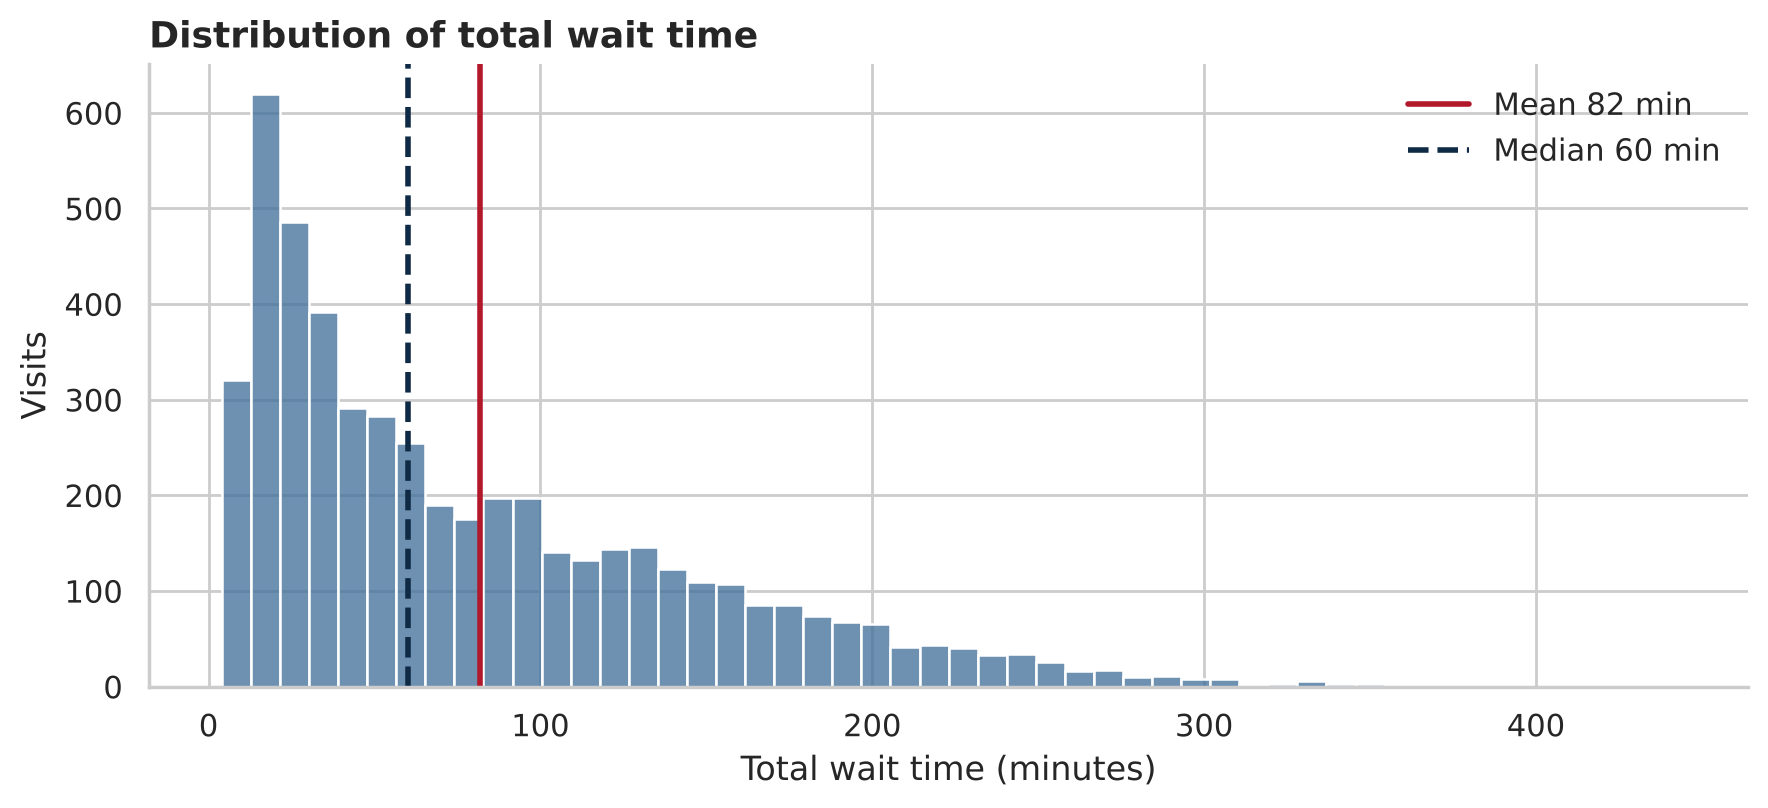

In [7]:
save(plot_wait_distribution(df), "wait_distribution.png")

The distribution is right-skewed, so the mean (82 minutes) sits well above the median (60). The long tail is real, mostly low-urgency patients, so it is kept rather than capped.

## 4. Patient flow

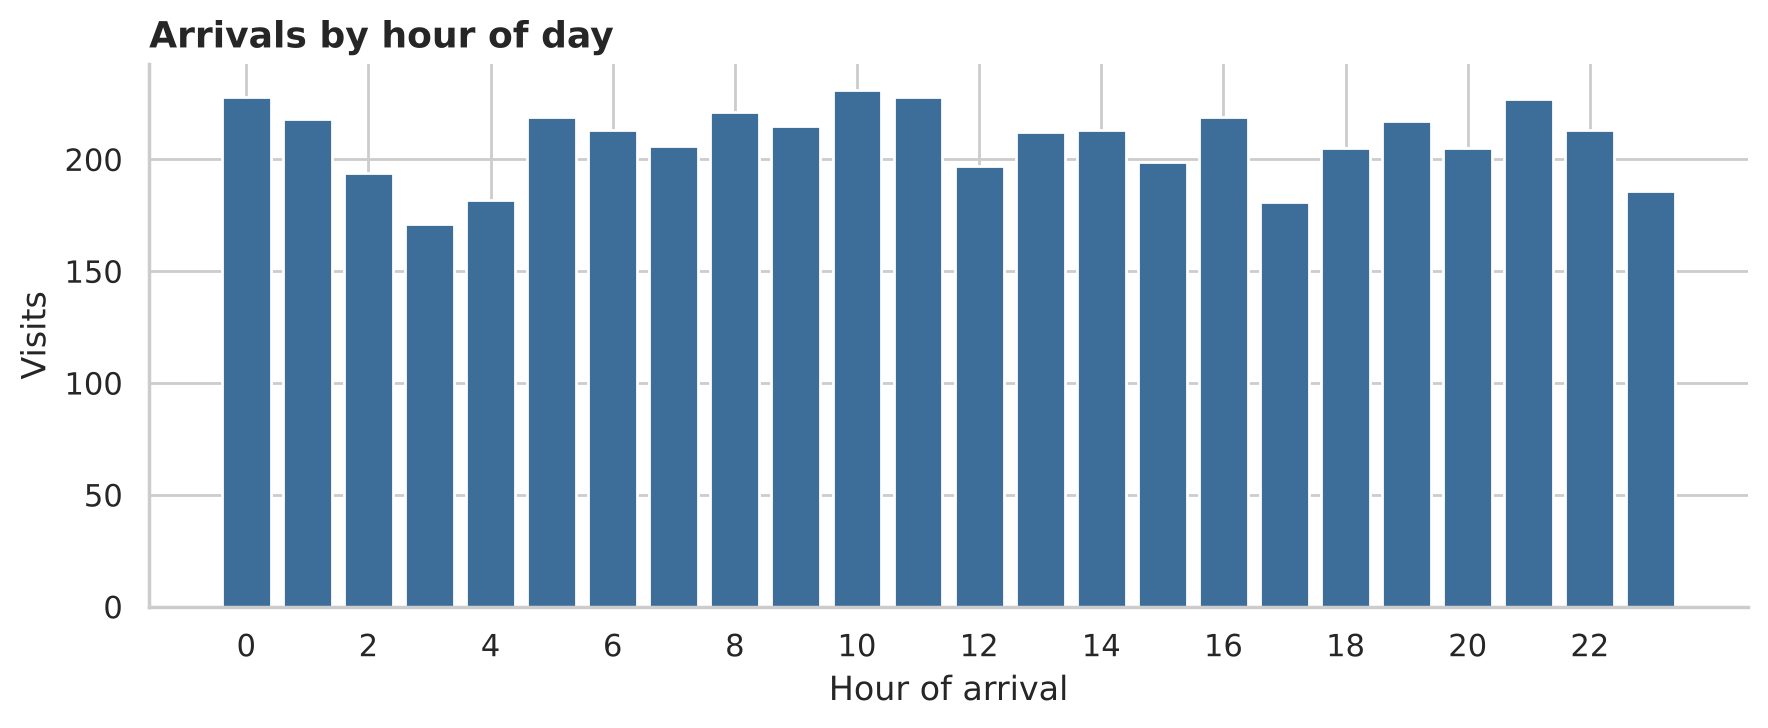

In [8]:
save(plot_arrivals_by_hour(df), "arrivals_by_hour.png")

In [9]:
wait_summary(df, "Hospital Name")

,Hospital Name,visits,mean_wait,median_wait,p90_wait
0,Northside Community Hospital,999,81.8,57.0,187.0
1,Riverside Medical Center,1023,81.8,60.0,177.0
2,Springfield General Hospital,994,82.7,60.0,179.0
3,St. Mary’s Regional Health,995,81.9,63.0,182.0
4,Summit Health Center,989,81.4,60.0,185.0


Arrivals are spread evenly across the day and across hospitals, and all five hospitals have almost the same average wait (81 to 83 minutes).

## 5. What drives the wait

### Urgency

In [10]:
wait_summary(df, "Urgency Level")

,Urgency Level,visits,mean_wait,median_wait,p90_wait
0,Critical,1242,18.4,17.0,30.0
1,High,1245,43.2,41.0,65.0
2,Medium,1291,93.7,89.0,138.0
3,Low,1222,173.5,165.0,249.0


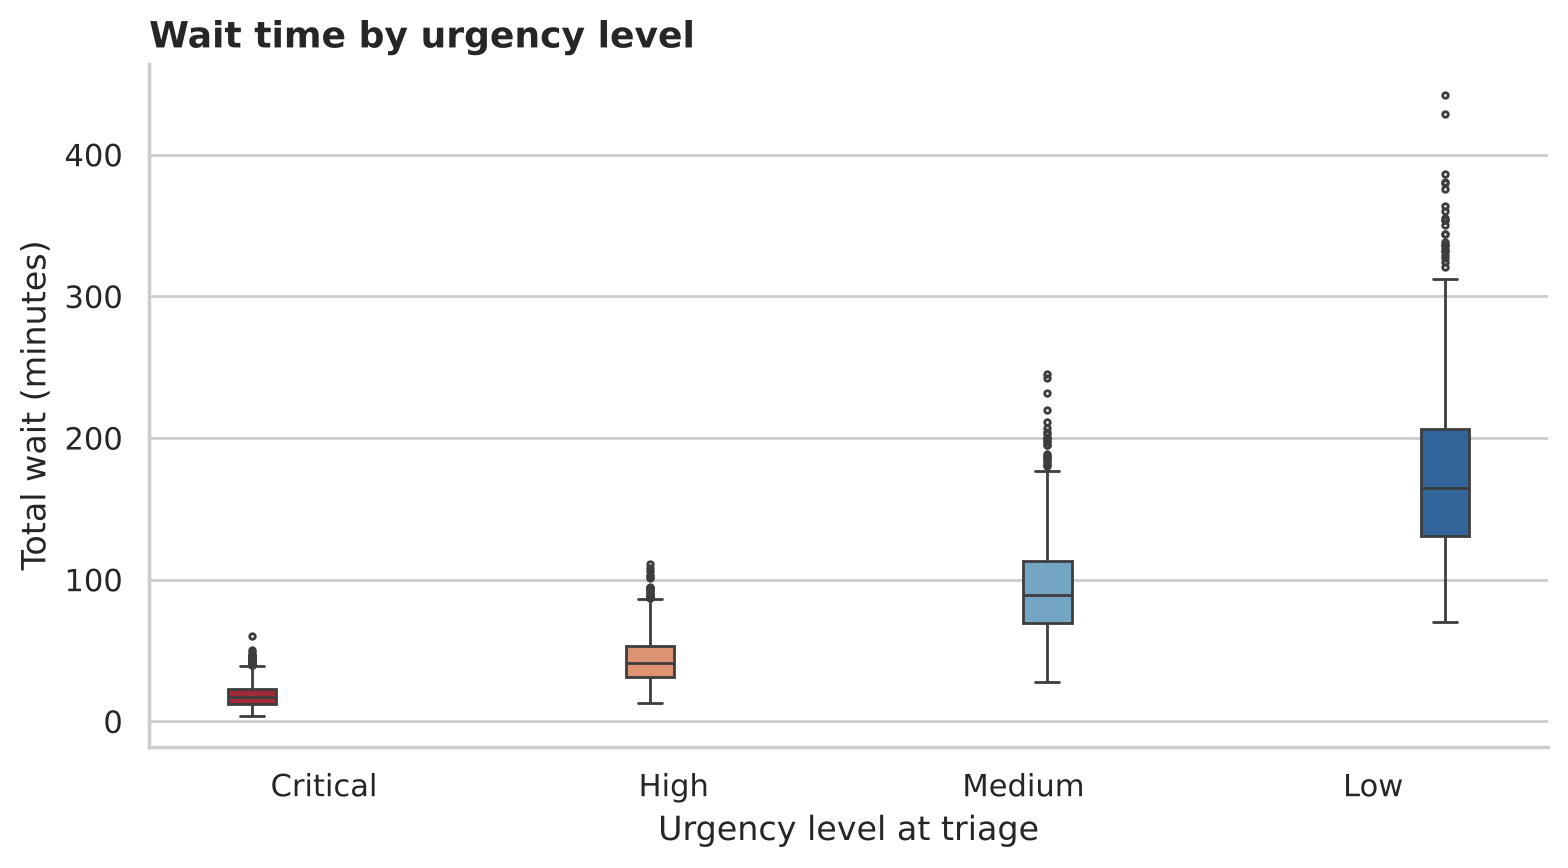

In [11]:
save(plot_wait_by_urgency(df), "wait_by_urgency.png")

In [12]:
stage_breakdown(df)

,Urgency Level,Registration,Triage,Seen by clinician,Total
0,Critical,2.1,4.0,12.3,18.4
1,High,5.6,11.0,26.5,43.1
2,Medium,14.8,26.2,52.7,93.7
3,Low,24.3,58.7,90.5,173.5


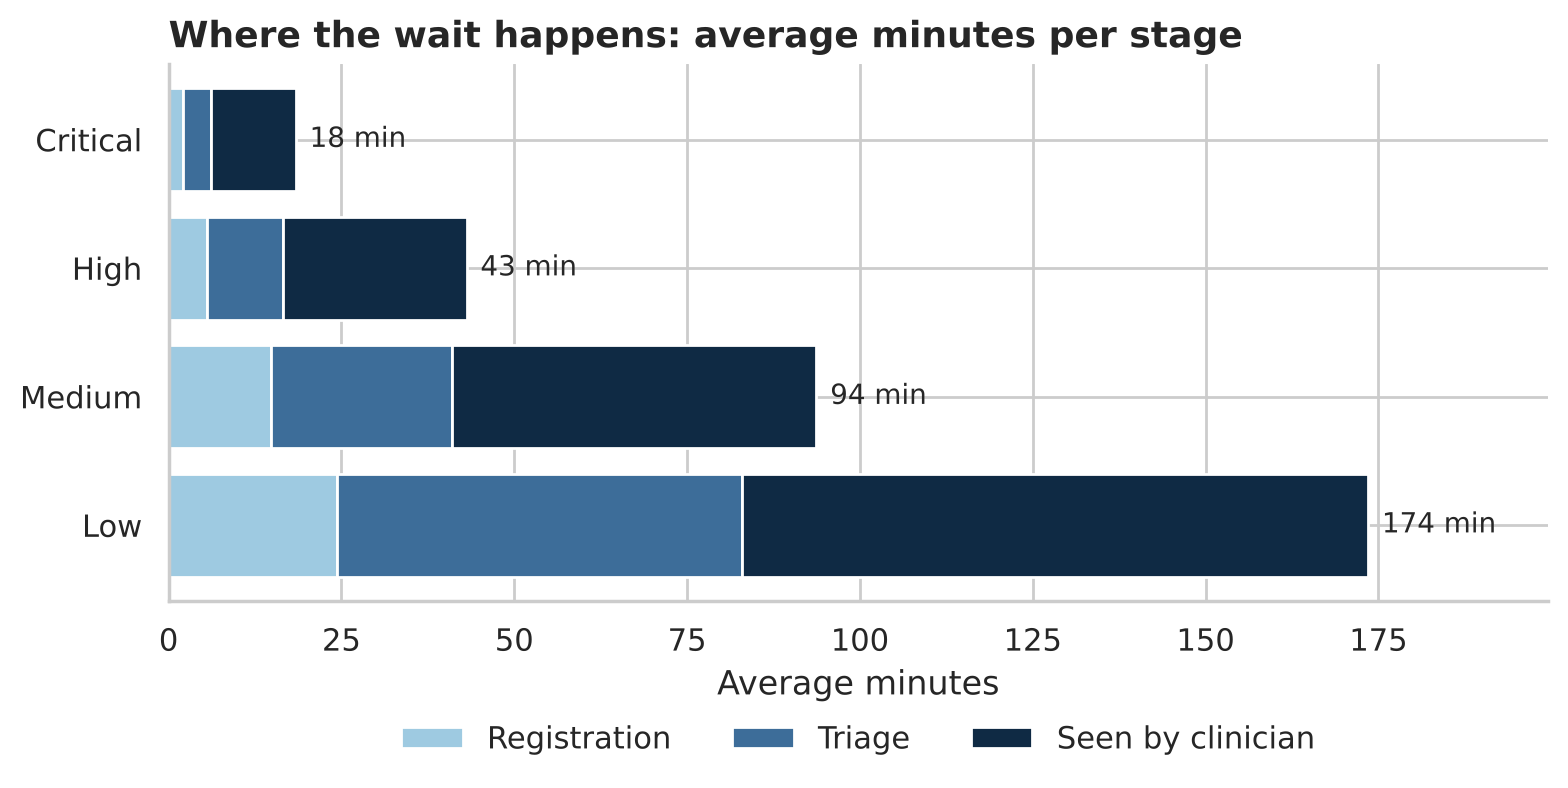

In [13]:
save(plot_stage_breakdown(df), "wait_by_stage.png")

### Time of day, day of week and season

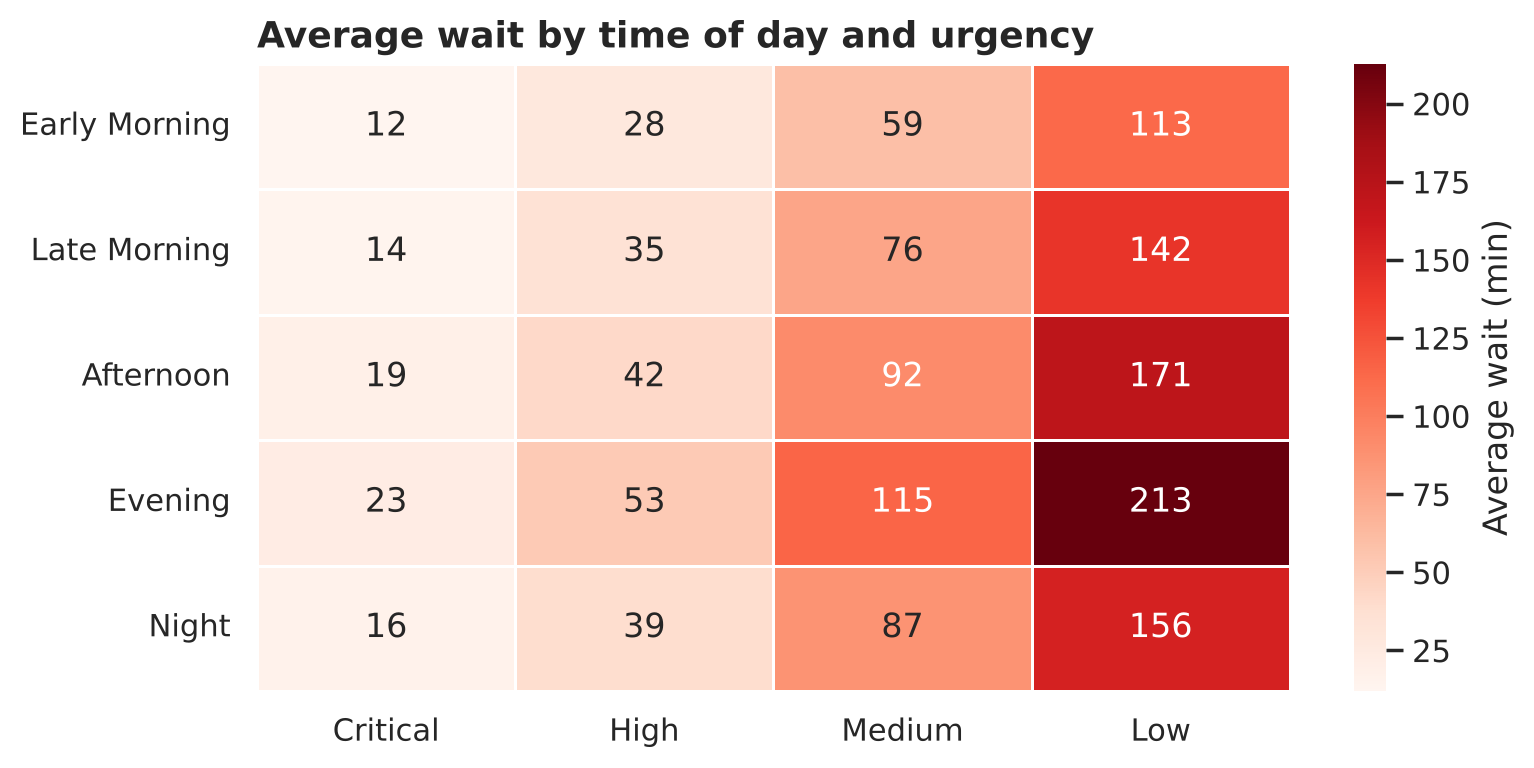

In [14]:
save(plot_wait_by_time_of_day(df), "wait_by_time_and_urgency.png")

In [15]:
display(wait_summary(df, "Day of Week"))
display(wait_summary(df, "Season"))

,Day of Week,visits,mean_wait,median_wait,p90_wait
0,Monday,768,101.6,71.0,232.0
1,Tuesday,741,79.1,57.0,177.0
2,Wednesday,674,78.3,54.5,179.0
3,Thursday,706,84.2,63.0,184.0
4,Friday,685,90.4,70.0,197.0
5,Saturday,701,72.1,58.0,157.0
6,Sunday,725,66.6,52.0,142.0


,Season,visits,mean_wait,median_wait,p90_wait
0,Spring,1227,72.4,55.0,158.0
1,Summer,1281,89.7,68.0,195.0
2,Fall,1234,66.4,48.5,149.0
3,Winter,1258,98.5,73.0,223.0


### Staffing

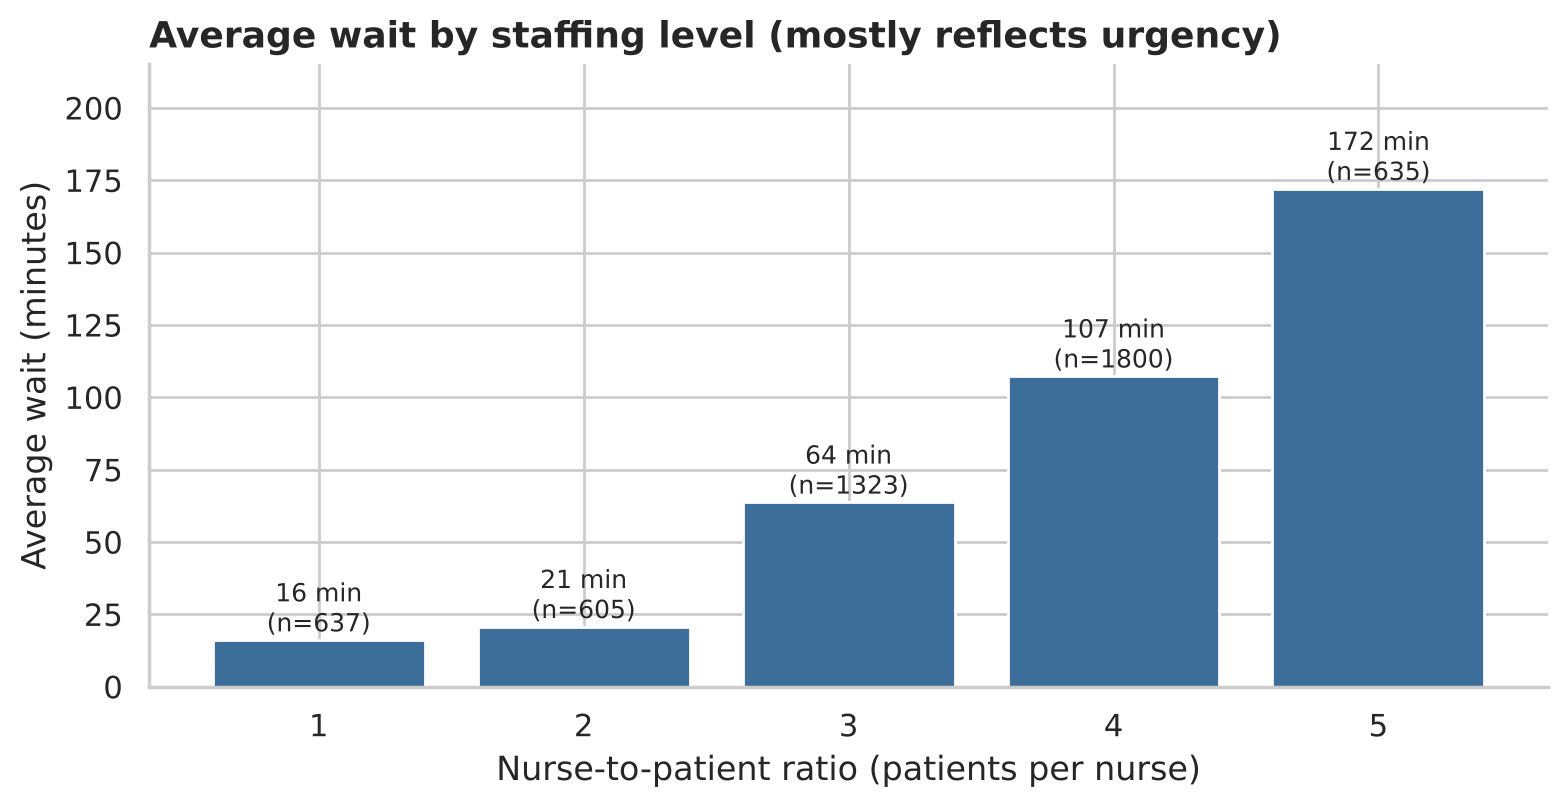

In [16]:
save(plot_wait_by_staffing(df), "wait_by_staffing.png")

In [17]:
print("Visits by urgency and nurse-to-patient ratio:")
display(pd.crosstab(df["Urgency Level"], df["Nurse-to-Patient Ratio"]))
print("Average wait by urgency and nurse-to-patient ratio:")
staffing_within_urgency(df)

Visits by urgency and nurse-to-patient ratio:


Nurse-to-Patient Ratio,1,2,3,4,5
Urgency Level,,,,,
Critical,637,605,0,0,0
High,0,0,633,612,0
Medium,0,0,690,601,0
Low,0,0,0,587,635


Average wait by urgency and nurse-to-patient ratio:


Nurse-to-Patient Ratio,1,2,3,4,5
Urgency Level,,,,,
Critical,16.1,20.7,NaN,NaN,NaN
High,NaN,NaN,38.9,47.6,NaN
Medium,NaN,NaN,86.5,102.0,NaN
Low,NaN,NaN,NaN,175.1,172.1


The staffing chart looks dramatic (16 minutes at ratio 1, 172 at ratio 5), but staffing follows urgency in this data: critical patients were only seen at ratios 1 and 2, low-urgency patients only at 4 and 5. Most of that gap is the urgency effect. Comparing within the same urgency level, one more patient per nurse adds about 5 to 16 minutes.

In [18]:
correlations(df)

Nurse-to-Patient Ratio     0.688
Specialist Availability    0.007
Facility Size (Beds)      -0.004
Hour                       0.005
Patient Satisfaction      -0.865
Name: Total Wait Time (min), dtype: float64

Specialist availability and facility size have no relationship with the wait. Patient satisfaction falls sharply as waits get longer (-0.87).

### Peak hours

In [19]:
peak = df[df["Hour"].isin(range(17, 21))][TARGET]
other = df[~df["Hour"].isin(range(17, 21))][TARGET]
stat, p = mannwhitneyu(peak, other)
print(f"Median wait, 17:00 to 20:59: {peak.median():.0f} min | other hours: {other.median():.0f} min")
print(f"Mann-Whitney U test p-value: {p:.3f}")

Median wait, 17:00 to 20:59: 63 min | other hours: 60 min
Mann-Whitney U test p-value: 0.350


Arrivals between 5 and 9 PM by the clock do not wait longer (the test is not significant), which matches the finding that clock hour carries little information here.

### Outcomes

In [20]:
outcome_by_urgency(df)

Patient Outcome,Admitted,Discharged,Left Without Being Seen
Urgency Level,,,
Critical,50.4,49.6,0.0
High,50.8,49.2,0.0
Medium,39.0,56.7,4.3
Low,8.7,75.1,16.2


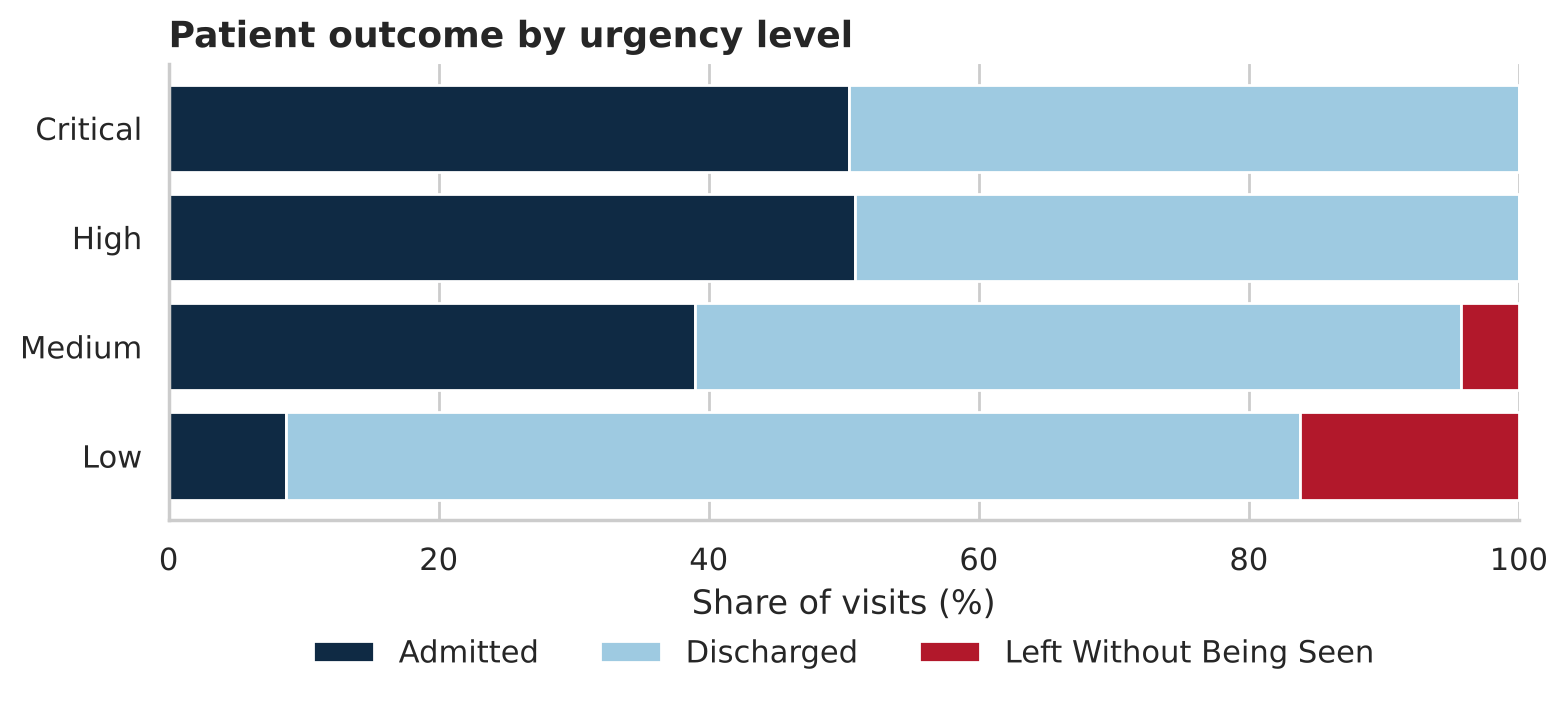

In [21]:
save(plot_outcome_by_urgency(df), "outcome_by_urgency.png")

In [22]:
wait_summary(df, "Patient Outcome")

,Patient Outcome,visits,mean_wait,median_wait,p90_wait
0,Admitted,1868,48.7,41.0,99.0
1,Discharged,2879,95.0,76.0,199.0
2,Left Without Being Seen,253,179.0,169.0,250.0


Patients who left without being seen had waited 179 minutes on average. 16% of low-urgency patients left, against none of the critical or high-urgency patients.

## 6. Modeling approach

The model should estimate the wait **when the patient arrives**, so it can only use information available at that moment:

- Urgency level, time of day, day of week, season, region, hospital
- Nurse-to-patient ratio, specialist availability, facility size, hour of arrival

Excluded:

- The three stage times, because they add up exactly to the target
- Patient outcome and satisfaction, because they are recorded after the visit

In [23]:
print("Features:", FEATURES)
print("Excluded:", LEAKY)

Features: ['Urgency Level', 'Time of Day', 'Day of Week', 'Season', 'Region', 'Hospital Name', 'Nurse-to-Patient Ratio', 'Specialist Availability', 'Facility Size (Beds)', 'Hour']
Excluded: ['Time to Registration (min)', 'Time to Triage (min)', 'Time to Medical Professional (min)', 'Patient Outcome', 'Patient Satisfaction']


## 7. Data leakage check

The first version of this project used every column as a feature and reported an R2 of 0.99999. The table below shows why that number was misleading.

In [24]:
leakage = leakage_demo(df)
leakage

,features,MAE,RMSE,R2
0,Arrival-time features only,12.191,17.906,0.931
1,"With stage times, outcome and satisfaction",1.398,2.677,0.998


With the stage times included, the model only has to add three numbers. That score says nothing about how well the wait can be predicted for a new patient.

## 8. Model comparison

All models use the same 80/20 split, plus 5-fold cross-validation on the full data.

In [25]:
comparison = compare_models(df)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison

,model,MAE,RMSE,R2,CV_R2_mean,CV_R2_std
0,Baseline (always predict the mean),54.694,68.207,-0.000,-0.001,0.001
1,Linear Regression,17.871,24.717,0.869,0.875,0.004
2,Random Forest,12.062,17.850,0.932,0.933,0.004
3,Gradient Boosting,11.461,16.983,0.938,0.938,0.004


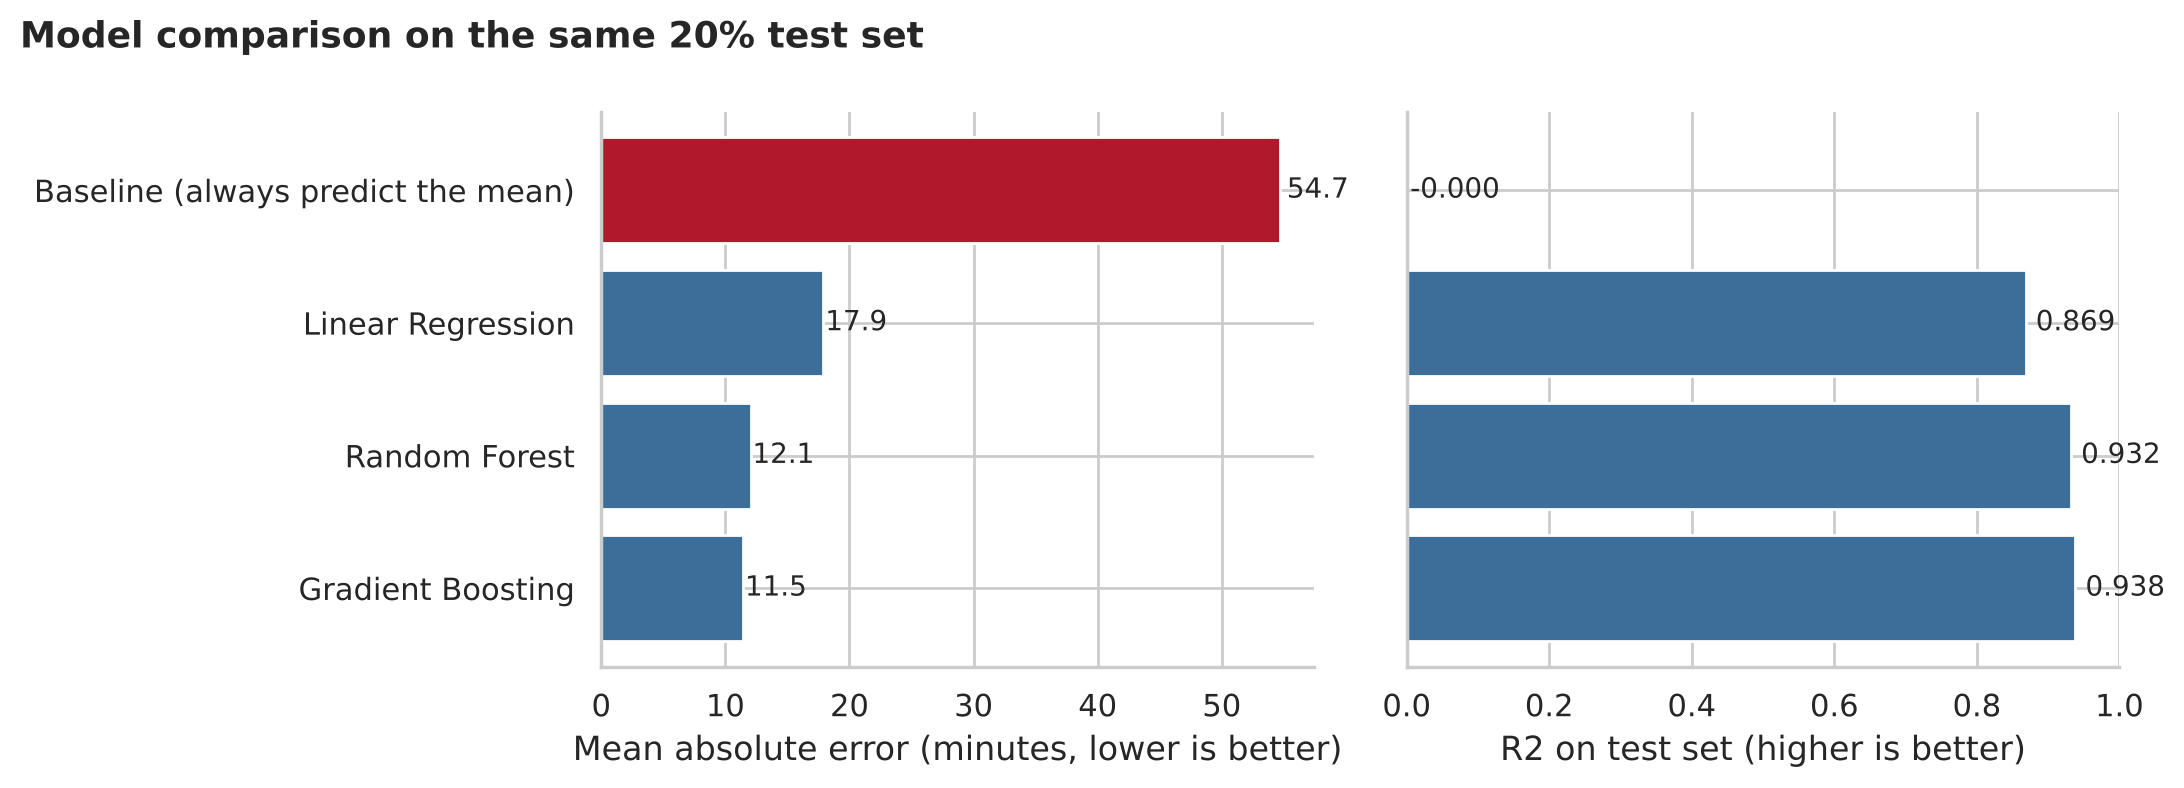

In [26]:
save(plot_model_comparison(comparison), "model_comparison.png")

In [27]:
preds = test_predictions(df)
print("Gradient Boosting test MAE:", round(preds["error"].abs().mean(), 1), "min")
print("Predictions within 15 minutes:", round((preds["error"].abs() <= 15).mean() * 100, 1), "%")
print()
print("MAE by urgency level:")
preds.groupby("Urgency Level", observed=True)["error"].apply(lambda e: e.abs().mean()).round(1)

Gradient Boosting test MAE: 11.4 min
Predictions within 15 minutes: 75.7 %

MAE by urgency level:


Urgency Level
Critical     4.0
High         6.6
Medium      14.9
Low         20.6
Name: error, dtype: float64

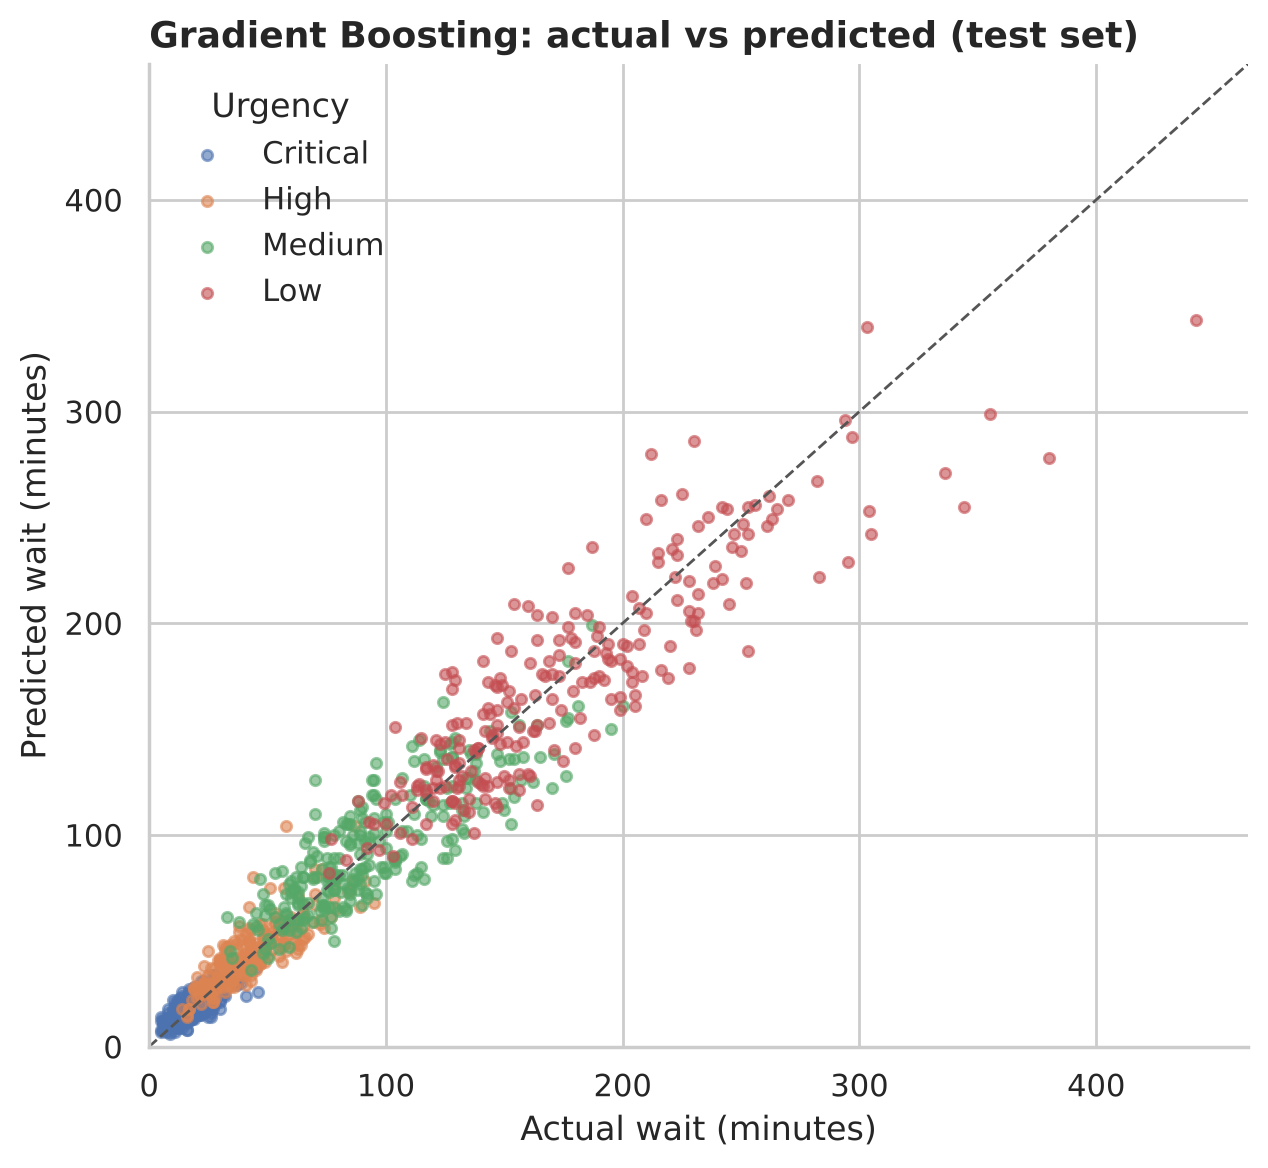

In [28]:
save(plot_actual_vs_predicted(preds), "actual_vs_predicted.png")

## 9. What the model relies on

In [29]:
importance = feature_importance(df)
importance.to_csv(RESULTS / "feature_importance.csv", index=False)
importance

,feature,MAE_increase_min
0,Urgency Level,51.62
1,Time of Day,9.38
2,Season,8.35
3,Day of Week,6.06
4,Nurse-to-Patient Ratio,2.54
5,Facility Size (Beds),0.14
6,Hour,0.09
7,Region,0.00
8,Hospital Name,-0.01
9,Specialist Availability,-0.05


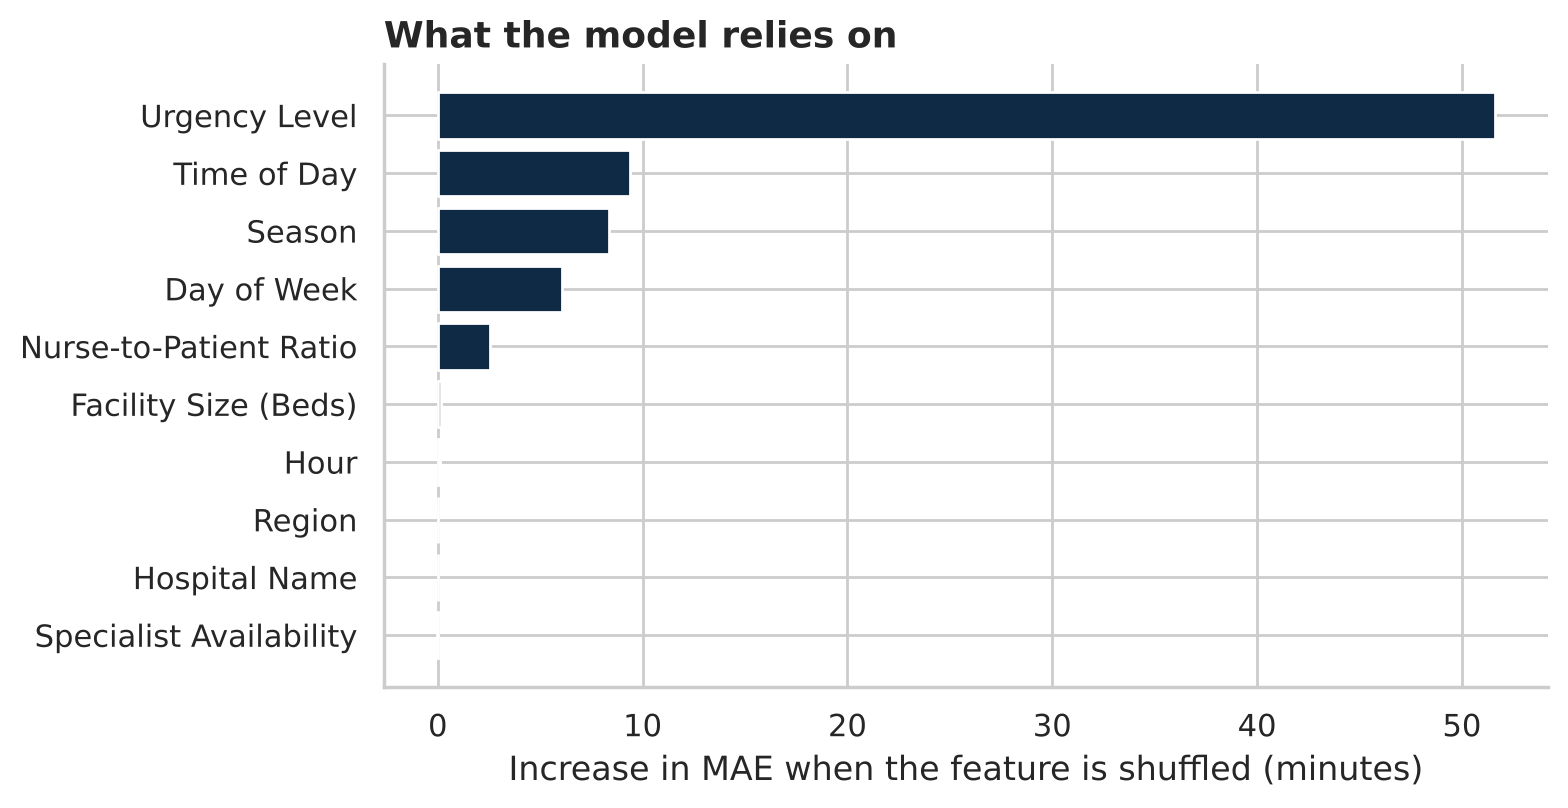

In [30]:
save(plot_feature_importance(importance), "feature_importance.png")

## 10. Findings and recommendations

1. **Urgency decides most of the wait.** Critical patients wait 18 minutes on average, low-urgency patients 174. Shuffling urgency raises the model's error by 52 minutes, far more than any other input.
2. **Time with the clinician is the longest stage** at every urgency level, about half of the total wait. Registration is the shortest.
3. **Evenings, Mondays and winter are the slowest.** Evening waits average 100 minutes against 52 in the early morning, Monday averages 102 against 67 on Sunday, and winter averages 99 against 66 in fall.
4. **Staffing helps less than it first appears.** Within the same urgency level, one more patient per nurse adds 5 to 16 minutes. Specialist availability and facility size show no effect.
5. **Long waits drive walk-outs.** 16% of low-urgency patients left without being seen, after waiting 179 minutes on average.
6. **The wait can be predicted from arrival information alone.** Gradient Boosting reaches R2 0.938 (cross-validated 0.938) with an average error of 11.5 minutes, against 54.7 minutes for a model that always predicts the average.

**Recommendations:** add staff to evening and Monday shifts and in winter, set up a fast track for low-urgency patients to cut walk-outs, and show arrivals an estimated wait based on this model.

**Limitations:** the dataset covers one year and five hospitals, staffing ratios are tied to urgency so their separate effect is hard to measure, and the `Time of Day` label does not match the recorded clock time for most visits.